# BERT Base Uncased: Masked Language Modelling and Sequence Classification

Covers:
- How BERT uses surrounding words to understand context
- What the tokenizer does and what its outputs mean
- How masked language modelling works
- How BERT is adapted for sequence classification
- What `TFAutoModelForSequenceClassification` and its outputs mean
- Fine-tuning and making predictions

**Model:** `bert-base-uncased`  
**Framework:** TensorFlow / Keras  
**Library:** Hugging Face Transformers

## 1. What is sequence classification?

Sequence classification assigns **one prediction to an entire input sequence**.

| Input text | Example target label |
|---|---|
| “The product is excellent.” | positive |
| “The delivery was disappointing.” | negative |
| “The experience was acceptable.” | neutral |

The input may be a sentence, paragraph, customer review, support ticket or document excerpt.

### Sequence classification versus token classification

- **Sequence classification:** one output for the complete input. Example: sentiment of a review.
- **Token classification:** one output for each token. Example: identify people, organizations and locations in a sentence.
- **Text generation:** predict subsequent tokens to produce new text.

A sequence classifier combines contextual information from the input and produces one final prediction.

```text
Input text
   |
   v
Tokenizer
   |
   v
Token IDs + attention mask
   |
   v
BERT encoder
   |
   v
Sequence representation (often the final [CLS] vector)
   |
   v
Classification head
   |
   v
Logits -> probabilities -> predicted label
```

## 2. What are BERT and DistilBERT?

### BERT

**BERT** stands for **Bidirectional Encoder Representations from Transformers**. It is a language representation model introduced by Google in 2018.

BERT uses the **encoder** part of the Transformer architecture. Self-attention allows each token representation to incorporate information from tokens to its left and right, subject to the attention mask.

BERT is pretrained on large text corpora using self-supervised objectives. The original BERT pretraining setup included:

- **Masked Language Modeling (MLM):** some input tokens are masked or corrupted, and the model learns to predict the original tokens.
- **Next Sentence Prediction (NSP):** an auxiliary objective in original BERT training to predict whether one segment follows another in the source text.

A pretrained BERT model is not automatically a sentiment classifier. For a particular sequence-classification task, a task-specific output layer is attached and the model is fine-tuned using labelled examples.

### BERT-base configuration

| Property | Value |
|---|---:|
| Transformer encoder layers | 12 |
| Hidden size | 768 |
| Attention heads per layer | 12 |
| Feed-forward/intermediate size | 3,072 |
| Original configured maximum sequence length | 512 tokens |

A hidden size of 768 means that each token is represented by a vector containing 768 numbers at the final encoder layer.

### DistilBERT

**DistilBERT** is a smaller, faster Transformer model created through **knowledge distillation**. In distillation, a smaller *student network* is trained to reproduce useful behaviour of a larger *teacher network*.

The commonly used `distilbert-base-uncased` architecture has:

| Property | BERT-base | DistilBERT-base |
|---|---:|---:|
| Encoder layers | 12 | 6 |
| Hidden size | 768 | 768 |
| Attention heads | 12 | 12 |
| Token type embeddings | Yes | No |
| Approximate parameter reduction | — | Around 40% fewer parameters |

DistilBERT is not simply BERT with half the layers deleted after training. It is trained using a distillation procedure so that the smaller model retains much of the larger model's language capability.

**Why use DistilBERT in this notebook?** It is generally lighter and quicker to run while preserving the core encoder-and-classification-head concepts.

**Checkpoint distinction:** `distilbert-base-uncased-finetuned-sst-2-english` is already fine-tuned for binary sentiment prediction on the SST-2 dataset. It is not merely a general pretrained language model.

In [ ]:
import tensorflow as tf
import transformers

print("TensorFlow:", tf.__version__)
print("Transformers:", transformers.__version__)

from transformers import (
    AutoTokenizer,
    TFAutoModel,
    TFAutoModelForMaskedLM,
    TFAutoModelForSequenceClassification,
)

## 2. What BERT learns

BERT stands for **Bidirectional Encoder Representations from Transformers**.

BERT is an encoder-only Transformer. It reads the tokens in a sentence and builds contextual representations for them. “Bidirectional” means that a token's representation can use information from tokens to its left and right.

For example:

- `The bank approved the loan.`
- `The river bank was muddy.`

The word `bank` has different meanings in these sentences. BERT uses the surrounding words to build different contextual representations.

`bert-base-uncased` is the base BERT model:
- 12 Transformer encoder layers
- 12 attention heads in each layer
- Hidden size of 768
- About 110 million parameters

“Uncased” means text is converted to lowercase during tokenization. Therefore, `France`, `FRANCE`, and `france` are treated alike by this tokenizer.

## 3. Load the tokenizer

```python
from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
```

**What each part means**

- `transformers`: the Hugging Face library.
- `AutoTokenizer`: a factory class. It reads the model's tokenizer configuration and selects the correct tokenizer implementation. For BERT, it selects a BERT-compatible WordPiece tokenizer.
- `from_pretrained(...)`: loads tokenizer files for a named model or a local model directory. Files are downloaded if they are not already cached.
- `"bert-base-uncased"`: the model repository identifier.

A tokenizer is not the neural network. It converts text into token IDs and prepares the inputs expected by the model.

For BERT, tokenization includes:
1. Lowercasing and basic text cleanup
2. Splitting words into WordPiece subword tokens
3. Mapping each token to an integer ID
4. Adding special tokens when requested
5. Creating attention masks and, when requested, padding or truncating sequences

In [ ]:
model_name = "bert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)

print(type(tokenizer))

## 5. Tokenization: converting text into model-readable inputs

A neural network operates on numbers, not raw text. A **tokenizer** converts text into tokens and maps each token to an integer ID from a vocabulary.

BERT commonly uses **WordPiece**, a subword-tokenization method.

### Why subword tokenization?

A word-level vocabulary would need an entry for every possible word, spelling variation and inflection. This creates a large vocabulary and still struggles with rare or unseen words.

WordPiece can break an uncommon word into smaller known pieces. A continuation piece often begins with `##`.

Illustrative example only:

```text
unwanted -> un + ##want + ##ed
```

The exact split depends on the checkpoint's vocabulary. The tokenizer performs two linked operations:

1. **Token splitting:** raw text becomes tokens.
2. **Vocabulary lookup:** each token is mapped to its integer vocabulary ID.

An integer ID is an index into the model's learned embedding table. It is not a numerical measure of the word's meaning.

## 4. See tokenization step by step

A word may be represented by one token or several subword tokens. This lets BERT handle many words using a fixed vocabulary.

`tokenize()` displays the token strings. `convert_tokens_to_ids()` maps those strings to the integer IDs stored in the vocabulary.

In [ ]:
sentence = "BERT understands language using context and learning from it."

tokens = tokenizer.tokenize(sentence)
token_ids = tokenizer.convert_tokens_to_ids(tokens)

print("Original text:", sentence)
print("Tokens:", tokens)
print("Token IDs:", token_ids)

## 5. Special tokens: `[CLS]` and `[SEP]`

BERT uses special tokens to mark the structure of its input.

- `[CLS]` is placed at the beginning of a sequence. Its final contextual representation is commonly used as the summary representation for sequence-level tasks such as sentiment classification.
- `[SEP]` marks the end of a sequence. It also separates two text segments when BERT receives a pair of sentences.
- `[PAD]` is used to make sequences in a batch the same length.
- `[MASK]` is used in the masked language modelling task.

The tokenizer adds the required special tokens when called with its normal default settings.

In [ ]:
encoded = tokenizer(
    "BERT understands language using context.",
    add_special_tokens=True
)

print("Input IDs:", encoded["input_ids"])
print("Tokens:", tokenizer.convert_ids_to_tokens(encoded["input_ids"]))

## 6. Tokenizer output: input IDs and attention mask

Calling the tokenizer returns a dictionary-like object.

- `input_ids`: integer IDs representing the tokens.
- `attention_mask`: `1` for real tokens and `0` for padding tokens. It tells the model which positions should be treated as actual input.
- `token_type_ids`: segment identifiers used by BERT for sentence pairs. For a single sentence, these are usually all zero. Some model/tokenizer combinations do not return this field.

Padding makes sequences in a batch the same length. Truncation shortens sequences that exceed the selected maximum length.

In [ ]:
sentences = [
    "BERT reads both left and right context.",
    "Transformers build contextual token representations."
]

batch = tokenizer(
    sentences,
    padding=True,
    truncation=True,
    max_length=32,
    return_tensors="tf"
)

for name, tensor in batch.items():
    print(name, tensor.shape)
    print(tensor.numpy())

### Understand the shapes

If a batch contains 2 sentences and the padded sequence length is 12:

- `input_ids` has shape `(2, 12)`.
- `attention_mask` has shape `(2, 12)`.
- If present, `token_type_ids` has shape `(2, 12)`.

The first dimension is the number of sentences. The second dimension is the number of token positions per sentence.

## 7. Load the BERT encoder

`TFAutoModel` loads the base Transformer encoder without a task-specific prediction head.

- `TFAutoModel`: the TensorFlow version of the automatic model factory for base models.
- `from_pretrained(model_name)`: loads the model configuration and pretrained weights for the selected checkpoint.
- `bert-base-uncased`: the pretrained checkpoint identifier.

The output contains contextual representations for every input token. It does not directly return a sentiment label.

In [ ]:
bert_encoder = TFAutoModel.from_pretrained(model_name)

outputs = bert_encoder(
    input_ids=batch["input_ids"],
    attention_mask=batch["attention_mask"],
    training=False
)

print("Last hidden state shape:", outputs.last_hidden_state.shape)

In [ ]:
from transformers import pipeline

In [ ]:
fill = pipeline("fill-mask", model="bert-base-uncased")

fill("The capital of France is [MASK].")

In [ ]:
from transformers import pipeline
gpt = pipeline("text-generation", model="gpt2")
gpt("Once upon a time in Bangalore,")[0]["generated_text"]

In [ ]:
import tensorflow as tf
import transformers
import safetensors
import keras

print("TensorFlow:", tf.__version__)
print("Transformers:", transformers.__version__)
print("Safetensors:", safetensors.__version__)
print("Keras:", keras.__version__)

In [ ]:
sentiment_model_name = "textattack/bert-base-uncased-SST-2"

sentiment = pipeline(
    "text-classification",
    model=sentiment_model_name
)

sentiment("The service was excellent and the staff were helpful.")

In [ ]:
reviews = [
    "I absolutely loved this product.",
    "The quality was poor and it stopped working.",
    "The delivery arrived yesterday."
]

sentiment(reviews)

In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

model_name = "textattack/bert-base-uncased-SST-2"

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Load pretrained, fine-tuned classification model
model = AutoModelForSequenceClassification.from_pretrained(model_name)

# Prepare input
text = "The product is excellent."

inputs = tokenizer(
    text,
    return_tensors="pt",
    padding=True,
    truncation=True
)

# Run inference
import torch

with torch.no_grad():
    outputs = model(**inputs)

# Extract logits
logits = outputs.logits

# Convert logits to probabilities
probabilities = torch.softmax(logits, dim=-1)

# Get predicted label
predicted_id = torch.argmax(probabilities, dim=-1).item()

print("Probabilities:", probabilities)
print("Predicted label:", model.config.id2label[predicted_id])

In [ ]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from transformers import AutoTokenizer

# --------------------------------------------------
# 1. Load the BERT tokenizer
# --------------------------------------------------

model_name = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(model_name)

# Convert input text into token IDs and attention masks
texts = [
    "The product is excellent.",
    "The service was very disappointing."
]

encoded = tokenizer(
    texts,
    padding=True,
    truncation=True,
    max_length=64,
    return_tensors="tf"
)

input_ids = encoded["input_ids"]
attention_mask = encoded["attention_mask"]


# --------------------------------------------------
# 2. BERT encoder
# --------------------------------------------------

# Conceptual step:
# Load the pretrained BERT encoder.
#
# In this environment, the Hugging Face TensorFlow
# checkpoint loader has a compatibility issue.
# Therefore, this is not an executable loader here.
#
# The encoder produces contextual representations
# for every token.

# bert_output = bert_encoder(
#     input_ids=input_ids,
#     attention_mask=attention_mask
# )


# --------------------------------------------------
# 3. Extract the [CLS] representation
# --------------------------------------------------

# BERT's final hidden state has shape:
# (batch_size, sequence_length, 768)
#
# The first token is [CLS].
# Its representation is commonly used for
# sequence-level classification.

# cls_output = bert_output.last_hidden_state[:, 0, :]


# --------------------------------------------------
# 4. Build a Keras classification head
# --------------------------------------------------

# This is a demonstration of the classification head.
# It receives a 768-dimensional BERT representation.

inputs = keras.Input(shape=(768,), name="cls_representation")

x = layers.Dropout(0.2)(inputs)

# Two output neurons:
# 0 = Negative
# 1 = Positive

outputs = layers.Dense(
    2,
    activation="softmax",
    name="sentiment_output"
)(x)

classifier = keras.Model(
    inputs=inputs,
    outputs=outputs
)


# --------------------------------------------------
# 5. Compile the model
# --------------------------------------------------

classifier.compile(
    optimizer=keras.optimizers.Adam(learning_rate=2e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


# --------------------------------------------------
# 6. Prediction (using a CLS representation)
# --------------------------------------------------

# Replace this demonstration input with the actual
# CLS representation produced by the BERT encoder.

# predictions = classifier.predict(cls_output)

# predicted_labels = tf.argmax(
#     predictions,
#     axis=1
# )

# print(predicted_labels)


## 9. From a pretrained encoder to sequence classification

Masked language modelling predicts a missing token. Sequence classification predicts a label for an entire input sequence.

Examples:
- Sentiment: positive or negative
- Support ticket routing: billing, technical support, account access
- Review classification: favourable or unfavourable

The BERT encoder can be reused for these tasks. A task-specific classification head is placed on top of the encoder.

A simplified view:

```text
Input text
   |
Tokenizer
   |
Input IDs + attention mask
   |
BERT encoder
   |
[CLS] representation (768 values)
   |
Classification head
   |
Logits (one score per label)
```

The classification head is task-specific. The pretrained base checkpoint does not already contain a trained sentiment head.

## 10. Load BERT for sequence classification

```python
from transformers import TFAutoModelForSequenceClassification

classifier = TFAutoModelForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=2
)
```

**What the API name means**

- `TF`: TensorFlow implementation.
- `Auto`: selects the correct model implementation from the checkpoint configuration.
- `ModelForSequenceClassification`: loads the Transformer encoder together with a sequence-classification head.
- `from_pretrained(...)`: loads pretrained encoder weights and creates the task head.
- `num_labels=2`: creates an output with two scores, for example negative and positive.

Because `bert-base-uncased` is a base checkpoint, its classification head is newly initialized. A warning about newly initialized classifier weights is expected. It means the head must be fine-tuned on labelled examples before its predictions are meaningful.

This is different from loading a checkpoint that has already been fine-tuned for sentiment classification.

## 15. Important distinction: base checkpoint versus fine-tuned checkpoint

| Checkpoint / model | What it contains | Suitable use |
|---|---|---|
| `bert-base-uncased` with `TFAutoModel` | Pretrained BERT encoder | Extract contextual representations |
| `bert-base-uncased` with `TFAutoModelForMaskedLM` | Pretrained BERT encoder and MLM head | Predict masked tokens |
| `bert-base-uncased` with `TFAutoModelForSequenceClassification` | Pretrained encoder and a newly initialized classification head | Fine-tune on labelled sequence data |
| A sentiment-fine-tuned BERT checkpoint | Encoder and a classification head already trained for sentiment | Sentiment inference |

The same pretrained BERT encoder can be adapted to different tasks by adding and training an appropriate task-specific head.

## **BERT Variants & Model Optimization**

### **1. Why are BERT variants needed?**

Original BERT is powerful but computationally expensive. It requires significant memory and processing time, particularly for large datasets and real-time applications.

Several variants were developed to improve training efficiency, reduce model size or improve performance.

### **2. Important BERT variants**

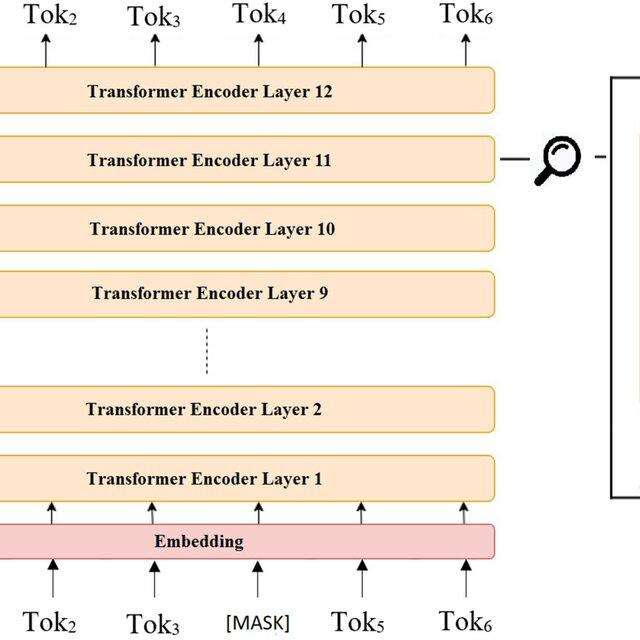

**BERT Base**

- 12 Transformer encoder layers
- 768 hidden dimensions
- 12 attention heads
- Approximately 110 million parameters
- General-purpose contextual language model

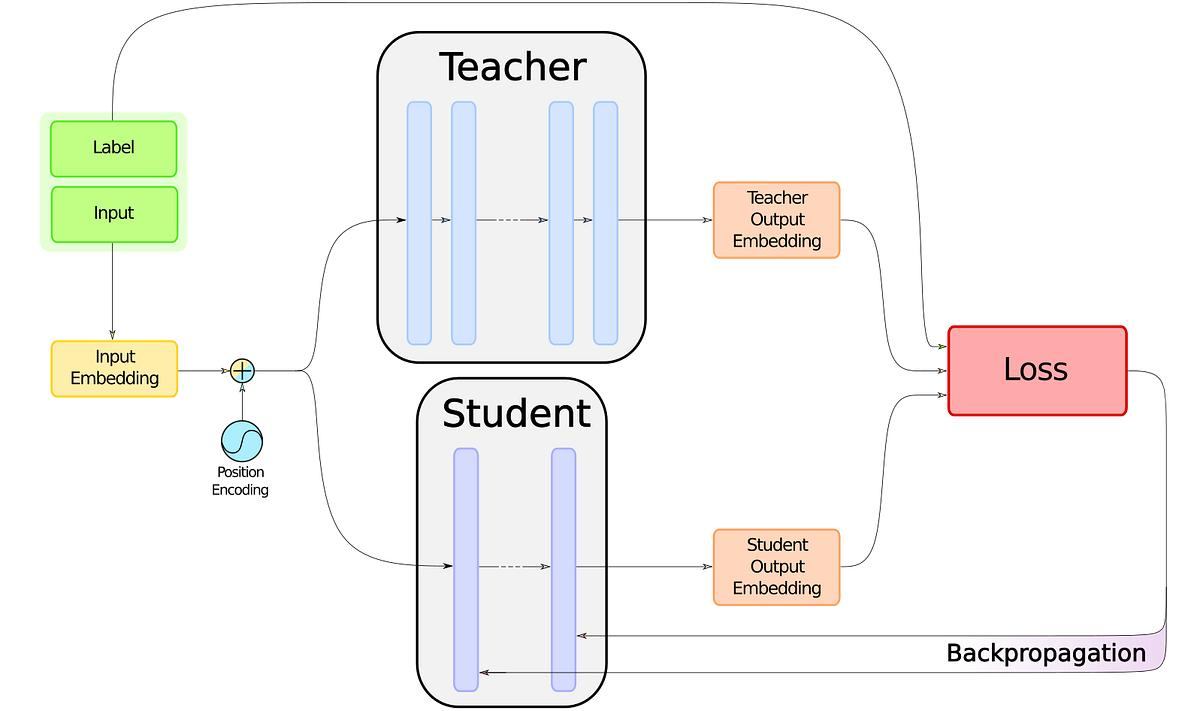

**DistilBERT**

- Approximately 66 million parameters
- 6 Transformer layers
- Approximately 40% smaller than BERT Base
- Knowledge distillation transfers knowledge from a larger teacher model to a smaller student model.
- Faster inference with much of BERT's performance retained.

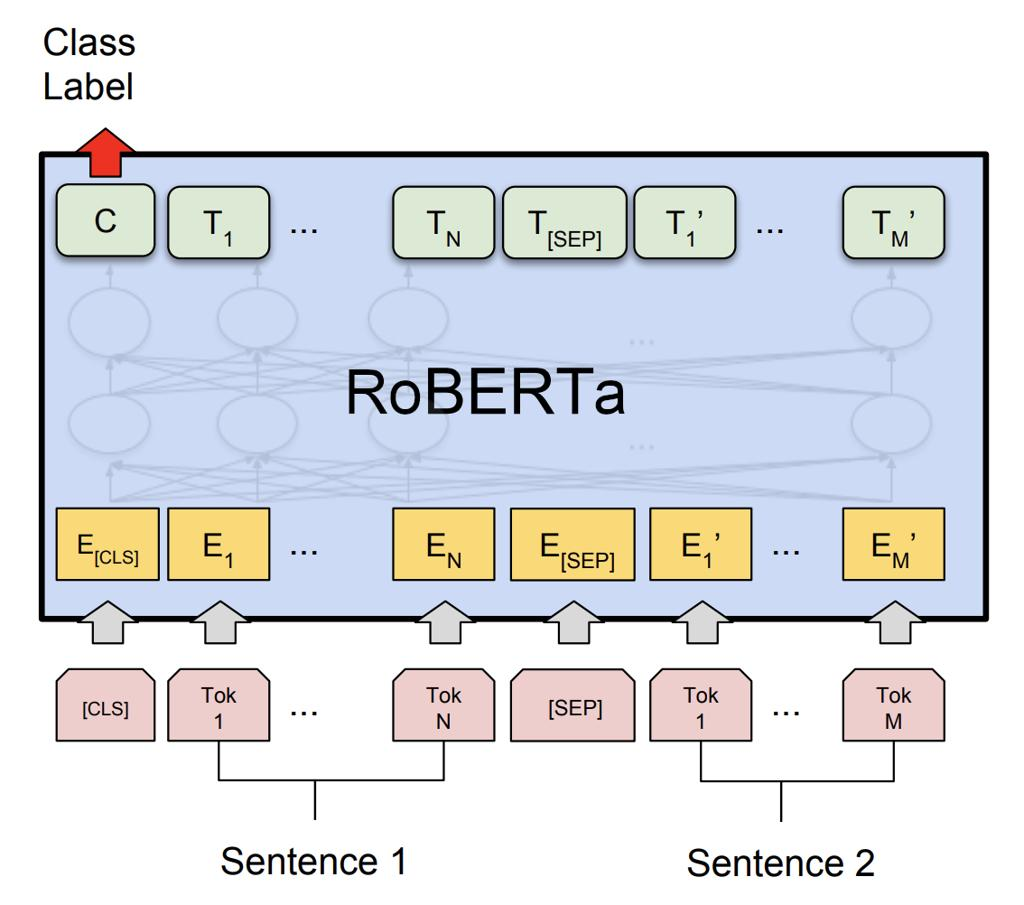

**RoBERTa**

- Robustly Optimized BERT Pretraining Approach.
- Removes Next Sentence Prediction (NSP).
- Uses dynamic masking.
- Trains with more data and optimized training settings.

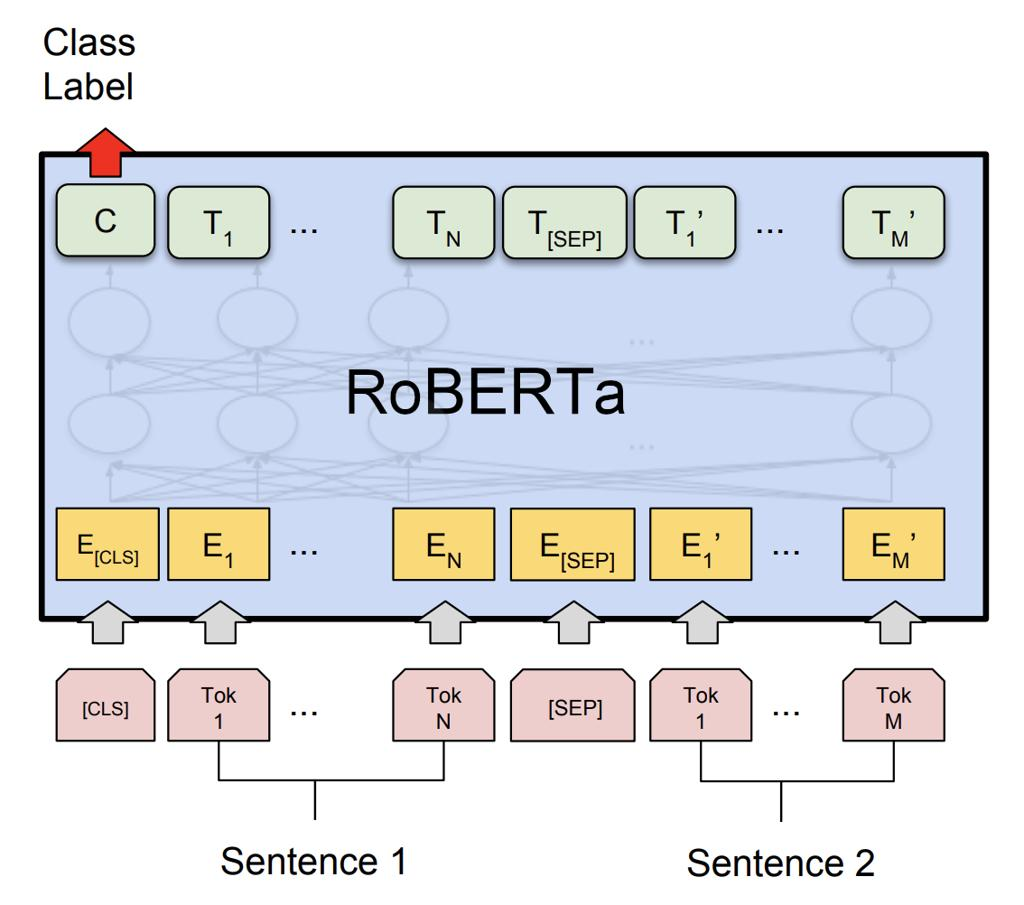

**ALBERT**

- A Lite BERT.
- Uses parameter sharing across Transformer layers.
- Factorizes embedding parameters.
- Reduces the number of model parameters.

### **3. Model Optimization Techniques**

Model optimization aims to reduce memory consumption, model size, inference latency and computational cost.

**A. Knowledge Distillation**

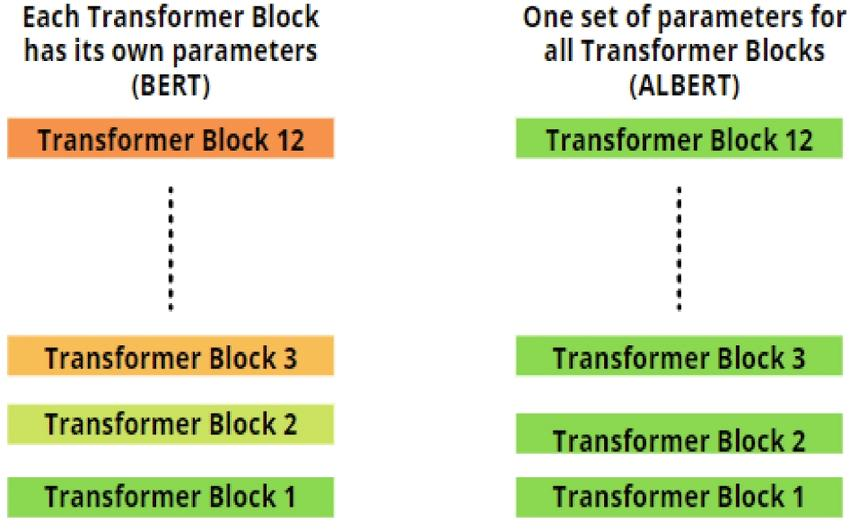
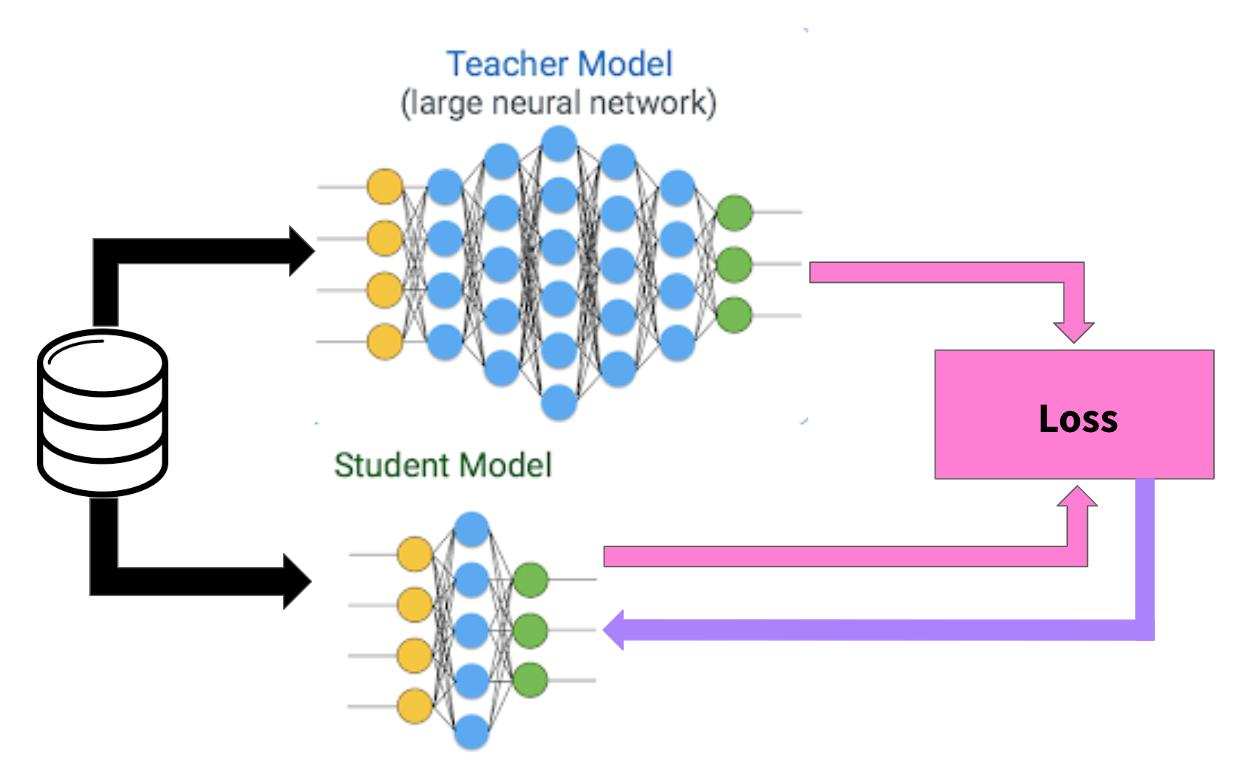
- A large model (teacher) transfers knowledge to a smaller model (student).
- The student learns from the teacher's output probabilities, in addition to the original training labels.
- DistilBERT is a well-known example.
- Useful when deploying NLP models on resource-constrained systems.

**B. Quantization**

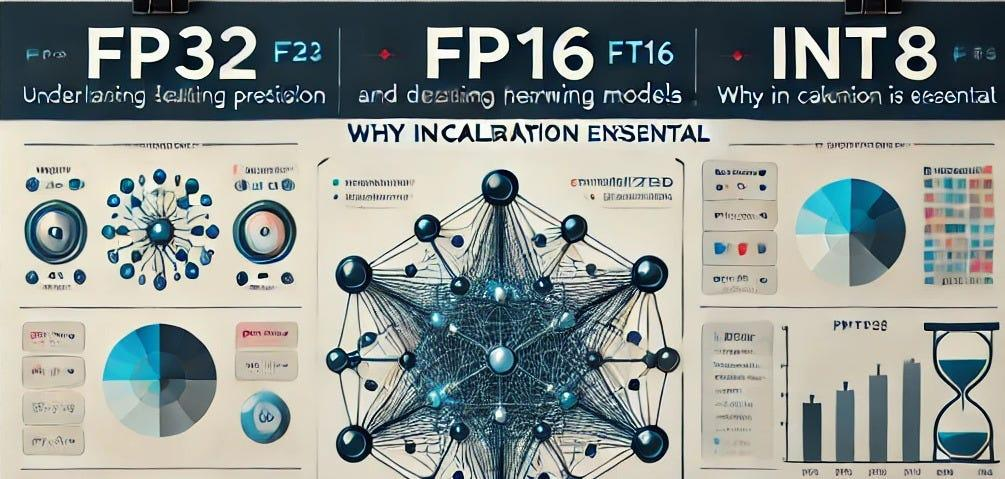

- Reduces the numerical precision used to represent model weights and sometimes activations.
- Example: FP32 (32-bit floating point) to INT8 (8-bit integer).
- Reduces memory requirements and can improve inference speed on supported hardware.
- May introduce a small accuracy reduction.

**C. Pruning**

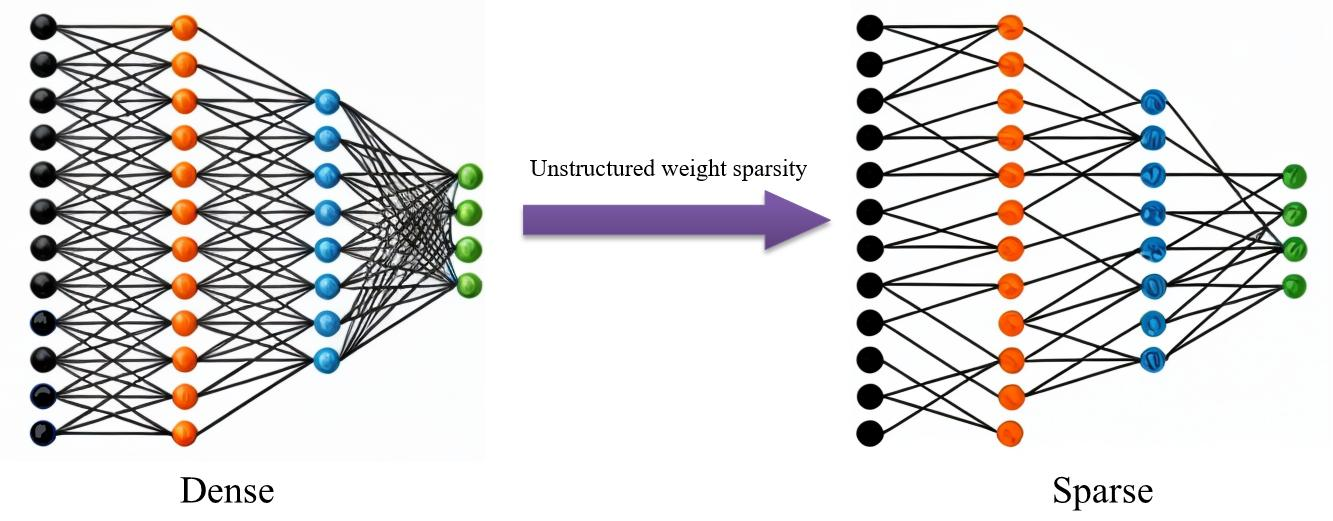

- Removes less important weights or structures from a neural network.
- Produces a sparse model.
- Can reduce computation and storage when supported by suitable hardware and inference software.

**D. Dynamic Padding**

- Pads each batch only to the length of its longest sequence rather than padding every input to a fixed maximum length.
- Reduces unnecessary computation on padding tokens.
- Particularly useful when input lengths vary considerably.

**E. Sequence Length Optimization**

- Transformer self-attention computation grows approximately quadratically with sequence length.
- Reducing sequence length can significantly reduce memory and computation.
- Avoid unnecessarily long input sequences.
- Truncation and appropriate chunking strategies can help.

### **4. Comparison of Optimization Techniques**

| Technique              | Primary benefit                   | Main trade-off                             |
| ---------------------- | --------------------------------- | ------------------------------------------ |
| Knowledge distillation | Smaller, faster model             | Student may lose some accuracy             |
| Quantization           | Lower memory and faster inference | Possible numerical accuracy loss           |
| Pruning                | Fewer active parameters           | Requires suitable sparse execution support |
| Dynamic padding        | Less wasted computation           | Batch preparation complexity               |
| Sequence reduction     | Lower attention computation       | Some context may be lost                   |

This demonstrates how different BERT-family models vary in architecture.

### **6. When to choose which model?**

| Requirement                     | Suitable choice                |
| ------------------------------- | ------------------------------ |
| General-purpose NLP             | BERT                           |
| Faster and smaller inference    | DistilBERT                     |
| Improved pretraining approach   | RoBERTa                        |
| Reduced parameter count         | ALBERT                         |
| Lower memory deployment         | Quantized BERT/DistilBERT      |
| Limited computational resources | DistilBERT or quantized models |

**Key takeaway:** BERT variants and optimization techniques make Transformer-based NLP applications more practical by balancing model accuracy, inference speed, memory usage and deployment cost.

### **5. Hands-on: Explore BERT versus DistilBERT**

The following code compares model configurations without requiring both models to be executed.

In [ ]:
from transformers import AutoConfig

models = [
    "bert-base-uncased",
    "distilbert/distilbert-base-uncased",
    "roberta-base",
    "albert-base-v2"
]

for model_name in models:

    config = AutoConfig.from_pretrained(model_name)

    print("\nModel:", model_name)
    print("Layers:", getattr(config, "num_hidden_layers", "N/A"))
    print("Hidden size:", getattr(config, "hidden_size", "N/A"))
    print("Attention heads:", getattr(config, "num_attention_heads", "N/A"))
    print("Vocabulary size:", config.vocab_size)

## 16. Summary

- BERT builds contextual representations using information from both directions.
- The tokenizer converts text into token IDs and attention masks.
- `[CLS]` is the first special token and is commonly used as the sequence representation.
- Masked language modelling predicts a masked token from its context.
- `TFAutoModel` loads the base BERT encoder.
- `TFAutoModelForMaskedLM` loads BERT with its masked-token prediction head.
- `TFAutoModelForSequenceClassification` loads BERT with a sequence-classification head.
- A classification head created from the base checkpoint must be fine-tuned before its predictions are useful.
- Logits are raw scores; softmax converts them into probabilities.